# 06 · A discovery workflow with PM4Py

An end-to-end example: simulate a log, discover models with different miners and noise thresholds, then compare LMP with PM4Py's token-based and alignment-based precision.

In [1]:
import os, warnings
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
warnings.filterwarnings("ignore", category=DeprecationWarning)

import language_mass_precision as lmp
import pm4py
import pandas as pd
pd.set_option("display.precision", 6)
import random
import matplotlib.pyplot as plt

In [2]:
reference = pm4py.parse_process_tree(
    "->('register', +('check_docs', 'check_credit'), *(X('assess', 'assess_expert'), 'request_info'),"
    " X('accept', 'reject'), 'notify')")
random.seed(7)
simulated = [tuple(event["concept:name"] for event in trace)
             for trace in pm4py.play_out(reference, parameters={"num_traces": 400})]

def add_noise(trace, rng):
    trace = list(trace)
    i = rng.randrange(1, len(trace) - 1)
    if rng.random() < 0.5:
        del trace[i]                                   # skipped activity
    else:
        trace[i], trace[i + 1] = trace[i + 1], trace[i]  # swapped activities
    return tuple(trace)

rng = random.Random(11)
traces = [add_noise(t, rng) if rng.random() < 0.15 else t for t in simulated]
log = lmp.traces_to_dataframe(traces)
print(len(traces), "cases,", len(set(traces)), "variants, of which",
      sum(t != s for t, s in zip(traces, simulated)), "cases carry noise")

400 cases, 145 variants, of which 57 cases carry noise


In [3]:
candidates = {f"IMf {noise:.1f}": pm4py.discover_petri_net_inductive(log, noise_threshold=noise)
              for noise in (0.0, 0.2, 0.4, 0.6, 0.8)}
candidates["heuristics"] = pm4py.discover_petri_net_heuristics(log)
candidates["reference"] = pm4py.convert_to_petri_net(reference)
candidates["flower"] = pm4py.convert_to_petri_net(
    pm4py.parse_process_tree("*(tau, X(" + ", ".join(f"'{a}'" for a in sorted(log['concept:name'].unique())) + "))"))

ranking = lmp.rank_models(log, candidates, length_prior="geometric")
ranking = ranking.set_index("model")[["rank", "status", "value", "lower", "upper", "dfa_states"]]
ranking["token_precision"] = [pm4py.precision_token_based_replay(log, *candidates[m]) for m in ranking.index]
ranking["alignment_precision"] = [pm4py.precision_alignments(log, *candidates[m]) for m in ranking.index]
ranking["token_fitness"] = [pm4py.fitness_token_based_replay(log, *candidates[m])["log_fitness"] for m in ranking.index]
ranking.sort_values("rank")

,rank,status,value,lower,upper,dfa_states,token_precision,alignment_precision,token_fitness
model,,,,,,,,,
reference,1,exact,0.999878,0.999878,0.999878,9,0.955885,0.955885,0.986665
IMf 0.2,2,exact,0.840013,0.840013,0.840013,14,0.702613,0.702613,0.992182
heuristics,3,exact,0.094458,0.094458,0.094458,11,0.955885,0.955885,0.989773
IMf 0.4,4,exact,0.066751,0.066751,0.066751,14,0.699712,0.699712,0.915559
IMf 0.0,5,exact,0.002947,0.002947,0.002947,53,0.484653,0.484653,1.000000
flower,6,exact,0.000010,0.000010,0.000010,2,0.290527,0.290527,1.000000
IMf 0.6,7,exact,0.000000,0.000000,0.000000,14,0.444444,0.444444,0.739519
IMf 0.8,7,exact,0.000000,0.000000,0.000000,14,0.444444,0.444444,0.739519


Noise separates the candidates, and LMP separates them more sharply than replay does.

* **IMf 0.0** fits every case, so it must absorb the noisy variants. Its language balloons (53 DFA states against 9 for the reference) and LMP drops to about 0.003 while alignment precision is still near 0.5.
* **IMf 0.6 / 0.8** filter so aggressively that none of the 145 variants is replayed in full (see `accepted_variants`). The numerator is empty and LMP is 0, the same as for any model that shares no trace with the log.
* **heuristics** matches the reference on token and alignment precision (0.956) yet scores an LMP of 0.094. That disagreement is worth a closer look.

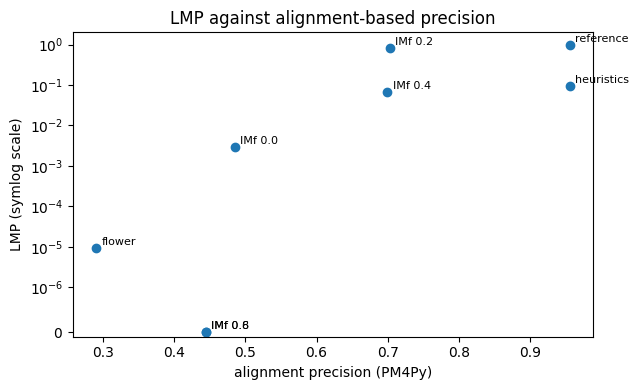

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(ranking["alignment_precision"], ranking["lower"])
for name, row in ranking.iterrows():
    ax.annotate(name, (row["alignment_precision"], row["lower"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_yscale("symlog", linthresh=1e-6); ax.set_ylim(-1e-7, 2)
ax.set_xlabel("alignment precision (PM4Py)"); ax.set_ylabel("LMP (symlog scale)")
ax.set_title("LMP against alignment-based precision"); fig.tight_layout()

## Why does LMP penalize the heuristics net?

Attribution answers it directly.

In [5]:
table = lmp.imprecision_attribution(log, *candidates["heuristics"], top_k=6)
table.assign(trace=table["trace"].map(" → ".join))[["trace", "length", "share_lower", "cumulative_share"]]

,trace,length,share_lower,cumulative_share
0,register → check_credit → check_docs → assess ...,5,0.110727,0.110727
1,register → check_credit → check_docs → assess ...,5,0.110727,0.221455
2,register → check_credit → check_docs → assess_...,5,0.110727,0.332182
3,register → check_credit → check_docs → assess_...,5,0.110727,0.442909
4,register → check_docs → check_credit → assess ...,5,0.110727,0.553637
5,register → check_docs → check_credit → assess ...,5,0.110727,0.664364


Every top trace stops before `notify`: the heuristics net lets a case end early. These short traces never occur in the log, and under a prior that favours shorter traces they hold most of the model's language mass. Escaping-edge precision counts the extra *activities* a model enables after each observed prefix; ending a case early is not an activity, so it never registers as an escape.

The two measures answer different questions. LMP measures language precision under a declared prior; replay-based measures look at escaping behaviour along the observed traces. Disagreement between them is informative, and attribution turns it into something a modeller can act on.